# Классификатор тональности русских твитов: TF-IDF + MLP

**Задача:** бинарная классификация твитов на позитивные и негативные на датасете RuTweetCorp.

**Подход:** классический NLP-пайплайн: очистка и лемматизация текста → векторизация TF-IDF → многослойный перцептрон (MLP).
Дополнительно разбирается, на какие слова опирается модель, и где у такого подхода заканчивается «понимание» текста.

**Содержание**
1. Загрузка и предобработка данных
2. Векторизация TF-IDF и обучение MLP
3. Интерпретация модели: анализ весов
4. Оценка качества и слабые места
5. Тот же MLP на PyTorch
6. Отчёт и выводы

**Запуск:** Google Colab (`Runtime → Run all`) или локально через Docker (`docker compose up -d`, см. README).

## 0. Подготовка окружения

В Colab большинство библиотек уже установлено, не хватает только морфологического анализатора `pymorphy3` для лемматизации.
В Docker-образе всё ставится из `requirements.txt`, поэтому установка выполняется только в Colab.

In [1]:
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    !pip install -q pymorphy3 pymorphy3-dicts-ru

Фиксируем `seed` (зерно генератора случайных чисел): разбиение на выборки, перемешивание и начальные веса нейросети
будут одинаковыми при каждом запуске, и результаты можно воспроизвести.

In [2]:
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import torch

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

pd.set_option('display.max_colwidth', 120)

## 1. Загрузка и предобработка данных

### 1.1 Загрузка датасета

[RuTweetCorp на Kaggle](https://www.kaggle.com/datasets/maximsuvorov/rutweetcorp) содержит два размеченных файла:
`positive.csv` и `negative.csv`. Текст твита лежит в колонке `ttext`.

Файлы скачиваются по прямой ссылке без аккаунта Kaggle и сохраняются в папку `data/`. При повторном запуске берутся с диска.

Метки классов: **позитив = 1**, **негатив = 0**. Модели бинарной классификации ожидают классы 0 и 1,
а `predict_proba` возвращает вероятность класса 1, то есть «вероятность позитива».

In [3]:
DATA_DIR = Path('../data') if Path('../data').is_dir() else Path('data')
DATA_DIR.mkdir(exist_ok=True)

KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/maximsuvorov/rutweetcorp/{name}'

DATASET_FILES = {'positive.csv': 1, 'negative.csv': 0}
LABEL_NAMES = {0: 'негатив', 1: 'позитив'}


def download_dataset_file(name: str) -> Path:
    csv_path = DATA_DIR / name
    if csv_path.exists():
        print(f'{name}: уже скачан')
        return csv_path

    print(f'{name}: скачиваю...')
    response = requests.get(KAGGLE_URL.format(name=name), timeout=300)
    response.raise_for_status()

    zip_path = DATA_DIR / f'{name}.zip'
    zip_path.write_bytes(response.content)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extract(name, DATA_DIR)
    zip_path.unlink()

    return csv_path


frames = []
for name, label in DATASET_FILES.items():
    part = pd.read_csv(download_dataset_file(name), usecols=['ttext'])
    part['label'] = label
    frames.append(part)

df = (
    pd.concat(frames, ignore_index=True)
    .rename(columns={'ttext': 'text'})
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(f'Размер датасета: {df.shape[0]:,} твитов, {df.shape[1]} колонки')
df.head(10)

positive.csv: уже скачан


negative.csv: уже скачан


Размер датасета: 226,834 твитов, 2 колонки


,text,label
0,мыс на меня обиделась:(\r\nя ей даже ничего не сделала:(,0
1,"аааааааааааааааааааа,не хочу на работу :(",0
2,"У меня какой-то особенный вид ушей! :D, некоторые вакуумные наушники в моих ушах просто не держатся!",1
3,"@simonovkon он неплохой человек в жизни. Я работала в шоу-бизе, со многими знакома. Встречаются очень хорошие люди....",0
4,"RT @Darina_Lo: Домааааа\nЕхали на такси, пели песни, отдыхали.\nКричали на улице:)\nМы настоящяя семья)",1
5,@passkrinDObroTA это ужасно:( так страашно,0
6,"RT @miwisakovab: Не грустим за летом, скоро будет следующее)",1
7,"Лежим с молой в постели , помогаем ему выбирать машину !)",1
8,"Я ВАС НАЙДУ, ОТРЕЖУ ПАЛЬЦЫ И ЗАСТАВЛЮ СОЖРАТЬ, ЕСЛИ ЕЩЕ РАЗ ДОБАВИТЕ МЕНЯ В ОБЩУЮ БЕСЕДУ ВКОНТАКТЕ С КАКОЙ-ТО ЛЕВОЙ ...",1
9,"@larkagerasimova Контоев Артем) рост, вес и тд интересует ?)",1


### 1.2 Первичный осмотр данных

Проверяем баланс классов, пропуски, дубликаты и длину твитов.

In [4]:
balance = pd.DataFrame({
    'твитов': df['label'].value_counts(),
    'доля': df['label'].value_counts(normalize=True).round(3),
}).rename(index=LABEL_NAMES)

print('Пустых текстов:', df['text'].isna().sum())
print('Дубликатов текста:', df['text'].duplicated().sum())
balance

Пустых текстов: 0
Дубликатов текста: 9394


,твитов,доля
label,,
позитив,114911,0.507
негатив,111923,0.493


In [5]:
words = df['text'].str.split().str.len()

words.groupby(df['label'].map(LABEL_NAMES)).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
негатив,111923.0,12.0,5.0,1.0,8.0,11.0,15.0,37.0
позитив,114911.0,12.5,4.7,1.0,9.0,12.0,16.0,40.0


### 1.3 Как размечен корпус: смайлики

Корпус размечали автоматически: твиты со «весёлыми» смайликами (`:)`, `)))`, `:D`) попали в позитив,
с «грустными» (`:(`, `(((`) - в негатив. Смайлики остались в текстах.

Посчитаем, в какой доле твитов каждого класса есть скобки:

In [6]:
brackets = pd.DataFrame({
    'есть ")"': df['text'].str.contains(')', regex=False),
    'есть "("': df['text'].str.contains('(', regex=False),
}).groupby(df['label'].map(LABEL_NAMES)).mean().round(3)

brackets

,"есть "")""","есть ""("""
label,,
негатив,0.000,0.947
позитив,0.829,0.000


**Что видно из таблицы:**
- в позитивных твитах `)` встречается в 82.9% случаев, а `(` не встречается ни разу;
- в негативных твитах `(` встречается в 94.7% случаев, а `)` не встречается ни разу.

Скобка почти однозначно выдаёт класс. Если её оставить, модель выучит правило «`)` → позитив, `(` → негатив»,
покажет высокую точность и при этом ничего не узнает о словах. Это **утечка данных (data leakage)**:
признак, по которому ставили метку, попал во входные данные. Поэтому при очистке текста (раздел 1.4)
скобки и смайлики удаляются обязательно.

**Другие наблюдения:**
- классы почти сбалансированы (50.7% / 49.3%), поэтому Accuracy будет честной метрикой;
- в среднем 12 слов на твит, длина у классов почти одинаковая;
- 9 394 текста повторяются (в основном ретвиты), с ними разберёмся после очистки;
- разметка шумная: она отражает смайлик, а не смысл. Например, угроза капслоком в строке 8 размечена как позитив
  (в ней был смайлик), а «он неплохой человек» в строке 3 — как негатив.

### 1.4 Очистка текста

TF-IDF считает слова «как есть»: `Привет`, `привет` и `ПРИВЕТ` для него три разных слова, а ссылки и никнеймы
только раздувают словарь. Функция `clean_text` по очереди:

| Шаг | Пример | Зачем |
|---|---|---|
| нижний регистр, `ё` → `е` | `ЁЛКА` → `елка` | одно слово — один признак |
| удаление ссылок | `http://t.co/GqG6iuE2` | каждая ссылка уникальна, тональности не несёт |
| удаление упоминаний | `@Darina_Lo` | имена пользователей — шум |
| удаление хештегов целиком | `#пятница` | по условию задания |
| всё, кроме русских букв, → пробел | `:)))`, `!!!`, `2`, `RT`, `:D` | пунктуация, цифры, латиница и **смайлики (утечка метки)** |
| 3+ одинаковые буквы подряд → одна | `домааааа` → `дома` | растянутые слова сводим к нормальным |
| смех в любом написании → `хаха` | `ахахах`, `хахаха`, `ахахха` | ~500 вариантов написания одного и того же сигнала; pymorphy не знает этих «слов» и разбирает их наугад (`ахахаха` → `ахахи`) |
| лишние пробелы и переносы строк → один пробел | `\n`, `   ` | аккуратный текст для токенизации |

Ссылки, упоминания и хештеги удаляются **до** фильтра букв: в них бывает кириллица (`@маша`, `#пятница`),
и фильтр оставил бы от них слово.

Вместо перечисления всего, что нужно удалить, используется «белый список»: оставляем только `а-я`.
Так в тексте гарантированно не останется ни одной скобки, эмодзи или латинского `:D`.

In [7]:
import re

URL_RE = re.compile(r'https?://\S+|www\.\S+')
MENTION_RE = re.compile(r'@\w+')
HASHTAG_RE = re.compile(r'#\w+')
NON_CYRILLIC_RE = re.compile(r'[^а-я]+')
REPEATED_CHAR_RE = re.compile(r'(.)\1{2,}')
LAUGH_RE = re.compile(r'\b(?=[ах]*х)(?=[ах]*а)[ах]{3,}\b')


def clean_text(text: str) -> str:
    text = text.lower().replace('ё', 'е')
    text = URL_RE.sub(' ', text)
    text = MENTION_RE.sub(' ', text)
    text = HASHTAG_RE.sub(' ', text)
    text = NON_CYRILLIC_RE.sub(' ', text)
    text = REPEATED_CHAR_RE.sub(r'\1', text)
    text = LAUGH_RE.sub('хаха', text)
    return ' '.join(text.split())


examples = [
    'RT @Darina_Lo: Домааааа\nЕхали на такси, пели песни :))) ахахаххаха',
    'Смотри http://t.co/GqG6iuE2 #пятница, какая ЁЛКА!!! :D',
    'не хочу на работу :( уже 2 часа ночи...',
]
for example in examples:
    print(f'{example!r}\n  → {clean_text(example)!r}\n')

'RT @Darina_Lo: Домааааа\nЕхали на такси, пели песни :))) ахахаххаха'
  → 'дома ехали на такси пели песни хаха'

'Смотри http://t.co/GqG6iuE2 #пятница, какая ЁЛКА!!! :D'
  → 'смотри какая елка'

'не хочу на работу :( уже 2 часа ночи...'
  → 'не хочу на работу уже часа ночи'



In [8]:
df['clean'] = df['text'].map(clean_text)

print('Скобок после очистки:', df['clean'].str.contains(r'[()]').sum())

Скобок после очистки: 0


### 1.5 Лемматизация

Русский язык богат формами: `люблю`, `любила`, `любим`, `любят` — для TF-IDF это четыре разных признака,
хотя смысл один. Нормализация сводит формы к одной:

- **стемминг** отрезает окончания по правилам (`котиков` → `котик`): быстро, но грубо, `людей` никогда не станет `человек`;
- **лемматизация** приводит слово к словарной форме по морфологическому словарю: `людей` → `человек`, `шёл` → `идти`.

Используется `pymorphy3` — морфологический анализатор русского языка. `parse(word)[0]` - самый вероятный разбор слова, `.normal_form` - его лемма.

Pymorphy возвращает леммы с буквой `ё` (`еще` → `ещё`), поэтому после лемматизации `ё` снова заменяется на `е`.

Ограничение: pymorphy разбирает каждое слово **отдельно, без контекста**, и выбирает самый частый разбор.
Поэтому `начала` (глагол) может стать `начало` (существительное), а `мне` → `я`, `нас` → `мы`.
Смех, сведённый при очистке к `хаха`, превращается в `хах`: главное, что у всех вариантов смеха одна лемма.

В корпусе около 2.7 млн словоупотреблений, но уникальных слов примерно в 15 раз меньше.
Декоратор `@lru_cache` запоминает результат для каждого слова, и повторные слова не разбираются заново.

In [9]:
from functools import lru_cache

import pymorphy3

morph = pymorphy3.MorphAnalyzer()


@lru_cache(maxsize=None)
def lemmatize_word(word: str) -> str:
    return morph.parse(word)[0].normal_form.replace('ё', 'е')


def lemmatize(text: str) -> str:
    return ' '.join(lemmatize_word(word) for word in text.split())


for example in ['любила', 'людей', 'шел', 'лучшего', 'еще', 'не', 'хочу']:
    print(f'{example:>8} → {lemmatize_word(example)}')

  любила → любить
   людей → человек
     шел → идти
 лучшего → хороший
     еще → еще
      не → не
    хочу → хотеть


In [10]:
%%time
df['lemma'] = df['clean'].map(lemmatize)

print('Уникальных слов разобрано:', lemmatize_word.cache_info().currsize)

Уникальных слов разобрано: 160728
CPU times: user 18.7 s, sys: 35.4 ms, total: 18.8 s
Wall time: 18.8 s


In [11]:
df[['text', 'clean', 'lemma']].sample(8, random_state=RANDOM_STATE)

,text,clean,lemma
215081,"“@kasimov_d_n: @tashkentgirl Ты уже начала мне верить? )))”да скоро я буду верить всем,всем кто говорит хотя бы вежл...",ты уже начала мне верить да скоро я буду верить всем всем кто говорит хотя бы вежливо,ты уже начало я верить да скоро я быть верить весь весь кто говорить хотя бы вежливый
220754,RT @JaneAir44660366: о чем можно вообще говорить) http://t.co/3fEZoyWfG0,о чем можно вообще говорить,о чем можно вообще говорить
60463,я ни когда не думал что буду так сильно скучать(((,я ни когда не думал что буду так сильно скучать,я ни когда не думать что быть так сильно скучать
213263,"@EvaKand До меня докопались они на улице по поводу телефона, думаю, от обиды, что я переписал их номера значков и фа...",до меня докопались они на улице по поводу телефона думаю от обиды что я переписал их номера значков и фамилии ну я в...,до я докопаться они на улица по повод телефон думать от обида что я переписать они номер значок и фамилия ну я всегд...
113055,Не надо связываться с моей учительницей по физкультуре:D,не надо связываться с моей учительницей по физкультуре,не надо связываться с мой учительница по физкультура
217274,"ПИТЕРЦЕВ,\r\nВИКА,\r\nСАША..\r\nМНЕ НЕ ХВАТАЕТ ТЕХ РАЗГОВОРОВ :( \r\nЯ СКУЧАЮ ПО ВАМ ((((",питерцев вика саша мне не хватает тех разговоров я скучаю по вам,питерец вика саша я не хватать тот разговор я скучать по вы
12325,@svetik_by ты сёння была ў чорнай шапцы і партфелем? ці я абазнаўся?),ты сення была чорнай шапцы партфелем ц я абазна ся,ты сенний быть чорнать шапец партфель ц я абазный ся
5133,RT @OlyaTaylor: Кто- то громче нас с Аней сегодня смеялся в столовой((((,кто то громче нас с аней сегодня смеялся в столовой,кто то громкий мы с аня сегодня смеяться в столовая


### 1.6 Пустые тексты и дубликаты

После очистки часть твитов становится пустой (в них были только ссылки, упоминания или смайлики),
а часть - одинаковой: ретвиты, «спасибо», «доброе утро» и т.п.

- **Пустые тексты** удаляем: модели нечего по ним предсказывать.
- **Тексты с противоречивыми метками** (один и тот же текст встречается и в позитиве, и в негативе) удаляем все:
  правильного ответа для них нет, это чистый шум разметки.
- **Дубликаты** оставляем по одному. Если одинаковый текст попадёт и в обучающую, и в тестовую выборку,
  модель будет проверяться на том, что уже «видела», и метрики окажутся завышенными.

Дубликаты ищем по колонке `lemma`: именно её увидит модель.

In [12]:
stats = {'исходно': len(df)}

df = df[df['lemma'] != '']
stats['без пустых'] = len(df)

conflicting = df.groupby('lemma')['label'].transform('nunique') > 1
print('Примеры текстов с противоречивыми метками:', df.loc[conflicting, 'lemma'].value_counts().head(5).index.tolist())
df = df[~conflicting]
stats['без противоречивых меток'] = len(df)

df = df.drop_duplicates(subset='lemma').reset_index(drop=True)
stats['без дубликатов'] = len(df)

pd.Series(stats, name='твитов').to_frame()

Примеры текстов с противоречивыми метками: ['хах', 'спасибо', 'да', 'привет', 'спокойный ночь']


,твитов
исходно,226834
без пустых,226717
без противоречивых меток,225982
без дубликатов,210421


In [13]:
df['label'].value_counts(normalize=True).rename(index=LABEL_NAMES).round(3)

label
позитив    0.508
негатив    0.492
Name: proportion, dtype: float64

### 1.7 Проверка: на какие слова можно опираться

Прежде чем обучать модель, посмотрим на простую статистику: в какой доле твитов со словом этот твит позитивный.
Берём слова, которые встречаются хотя бы в 300 твитах. Если бы после очистки осталась утечка
(например, смайлик кириллицей вроде `:ДДД`), здесь всплыли бы «слова» с долей ровно 0 или 1.

In [14]:
from collections import Counter

doc_freq = {label: Counter() for label in LABEL_NAMES}
for text, label in zip(df['lemma'], df['label']):
    doc_freq[label].update(set(text.split()))

word_stats = pd.DataFrame({
    'негатив': pd.Series(doc_freq[0]),
    'позитив': pd.Series(doc_freq[1]),
}).fillna(0).astype(int)
word_stats = word_stats[word_stats.sum(axis=1) >= 300]
word_stats['доля позитива'] = (word_stats['позитив'] / word_stats.sum(axis=1)).round(3)
word_stats = word_stats.sort_values('доля позитива')

pd.concat(
    [word_stats.head(10).reset_index(names='слово'), word_stats.tail(10)[::-1].reset_index(names='слово')],
    axis=1,
    keys=['самые «негативные»', 'самые «позитивные»'],
)

самые «негативные»                               самые «позитивные»          \
               слово негатив позитив доля позитива              слово негатив   
0           печально     386      24         0.059            приятно     104   
1             обидно     762      54         0.066        поздравлять      84   
2            грустно     583      41         0.066                хах    1158   
3             печаль     471      34         0.067            обожать      99   
4             ужасно     770      96         0.111                ура      96   
5           заболеть     715      93         0.115            спасибо     659   
6          сожаление     328      47         0.125               мило      63   
7              жалко     819     132         0.139          спокойный      85   
8            ужасный     583      95         0.140         счастливый     134   
9                увы     271      44         0.140           приятный     103   

                         
  позитив доля позитива  
0     785         0.883  
1     493         0.854  
2    6614         0.851  
3     522         0.841  
4     505         0.840  
5    3429         0.839  
6     317         0.834  
7     384         0.819  
8     589         0.815  
9     450         0.814

**Итоги предобработки:**
- из 226 834 твитов осталось 210 421: удалены пустые после очистки, тексты с противоречивыми метками и дубликаты;
- баланс классов сохранился (50.8% / 49.2%);
- наверху списков осмысленные слова (`печально`, `обидно`, `заболеть` против `приятно`, `поздравлять`, `обожать`),
  и ни одно не встречается только в одном классе: утечки через смайлики не осталось;
- смех (`хах`, ~7.8 тыс. твитов) - один из самых сильных позитивных сигналов. Без нормализации он был бы разбит на сотни написаний.
- около 1% твитов написаны на украинском или белорусском языке. Буквы `і`, `ї`, `є`, `ў` не входят в белый список,
  поэтому слова этих языков после очистки и лемматизации превращаются в редкие токены, которых нет в русском.
  Метки у этих твитов не хуже, чем у остальных (разметка по смайликам не зависит от языка), а редкие токены не попадут в словарь
  благодаря порогу `min_df` в TF-IDF. Отдельный фильтр по языку не применялся.

Для модели используется колонка `lemma`.

### 1.8 Разделение на обучающую и тестовую выборки

Модель проверяется на твитах, которых она **не видела** при обучении, иначе измеряется не умение обобщать, а память.

- 80% — обучающая выборка (train), 20% — тестовая (test);
- `stratify=y` сохраняет долю позитива и негатива одинаковой в обеих частях;
- тестовая выборка откладывается до раздела 4: все настройки подбираются только на train.

In [15]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['lemma'],
    df['label'],
    test_size=0.2,
    stratify=df['label'],
    random_state=RANDOM_STATE,
)

pd.DataFrame({
    'твитов': [len(y_train), len(y_test)],
    'доля позитива': [y_train.mean().round(3), y_test.mean().round(3)],
}, index=['train', 'test'])

,твитов,доля позитива
train,168336,0.508
test,42085,0.508


## 2. Векторизация TF-IDF и обучение MLP

### 2.1 Как работает TF-IDF

Нейросеть работает только с числами, поэтому каждый твит превращается в вектор длиной «размер словаря».
В позиции каждого слова стоит его вес:

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \cdot \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + N}{1 + \text{df}(t)} + 1$$

- **TF** (term frequency) — сколько раз слово $t$ встречается в твите $d$;
- **DF** (document frequency) — в скольких твитах из $N$ встречается слово;
- **IDF** (inverse document frequency) — чем реже слово в корпусе, тем больше вес: `обожать` важнее, чем `что`.

После этого `TfidfVectorizer` нормирует каждый вектор до длины 1, чтобы длинные и короткие твиты были сопоставимы.

Главное правило: векторизатор **обучается только на train** (`fit_transform`), а к test применяется готовый (`transform`).
Если обучить его на всех данных, словарь и IDF «подсмотрят» тестовую выборку — это утечка данных.

### 2.2 Подбор гиперпараметров векторизатора

Параметры, которые влияют на словарь:

- `min_df` — выбросить слова, которые встречаются меньше чем в N твитах (опечатки, редкие токены);
- `max_df` — выбросить слова, которые встречаются больше чем в доле твитов (слишком общие);
- `max_features` — оставить N самых частых слов;
- `ngram_range` — брать только отдельные слова `(1, 1)` или ещё и пары слов `(1, 2)`.

По умолчанию `TfidfVectorizer` берёт слова из двух и более букв, поэтому однобуквенные `я`, `в`, `и`, `с` в словарь не попадают, а `не` — попадает.

Обучение MLP занимает минуты, поэтому конфигурации векторизатора сравниваются на быстрой модели —
**логистической регрессии**. Это нейросеть из одного нейрона с сигмоидой (MLP без скрытых слоёв), она обучается за секунды.
Сравнение идёт на валидационной части, отрезанной от train (10%); тестовая выборка не используется.

In [16]:
%%time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    X_train_text, y_train, test_size=0.1, stratify=y_train, random_state=RANDOM_STATE,
)

has_ne = X_fit_text.str.split().apply(lambda words: 'не' in words)
print('Доля твитов со словом «не»:', round(has_ne.mean(), 3))

vectorizer_configs = [
    {'min_df': 1},
    {'min_df': 3},
    {'min_df': 5},
    {'min_df': 10},
    {'min_df': 5, 'max_features': 10_000},
    {'min_df': 5, 'max_df': 0.5},
    {'min_df': 5, 'max_df': 0.25},
    {'min_df': 5, 'ngram_range': (1, 2)},
]

rows = []
for params in vectorizer_configs:
    vec = TfidfVectorizer(**params)
    X_fit = vec.fit_transform(X_fit_text)
    X_val = vec.transform(X_val_text)
    probe = LogisticRegression(max_iter=1000).fit(X_fit, y_fit)
    rows.append({
        'параметры': str(params),
        'размер словаря': len(vec.vocabulary_),
        '«не» в словаре': 'не' in vec.vocabulary_,
        'accuracy (val)': round(accuracy_score(y_val, probe.predict(X_val)), 4),
    })

pd.DataFrame(rows)

Доля твитов со словом «не»: 0.291


CPU times: user 3min 49s, sys: 346 ms, total: 3min 49s
Wall time: 47.7 s


,параметры,размер словаря,«не» в словаре,accuracy (val)
0,{'min_df': 1},71650,True,0.7270
1,{'min_df': 3},21440,True,0.7273
2,{'min_df': 5},14468,True,0.7273
3,{'min_df': 10},8686,True,0.7243
4,"{'min_df': 5, 'max_features': 10000}",10000,True,0.7248
5,"{'min_df': 5, 'max_df': 0.5}",14468,True,0.7273
6,"{'min_df': 5, 'max_df': 0.25}",14467,False,0.7166
7,"{'min_df': 5, 'ngram_range': (1, 2)}",44264,True,0.7380


**Что показывает сравнение:**
- `min_df=5` уменьшает словарь примерно в 5 раз без потери качества: отбрасываются опечатки и редкие токены.
  Меньше признаков — меньше весов у MLP, быстрее обучение и меньше риск переобучения;
- `max_df=0.25` выбрасывает частицу `не` (она встречается почти в 30% твитов), и качество падает.
  Порог `max_df` нужно выбирать, глядя на данные, а не «на глаз»;
- биграммы `(1, 2)` дают прирост около 1 п.п.: пары вроде `не любить` частично возвращают порядок слов.
  К этому вернёмся в разделе 4, когда будем разбирать слабые места модели. Основная модель строится на отдельных словах,
  чтобы топ-20 в разделе 3 состоял из слов, как требует задание.

**Итоговые параметры:** `min_df=5`, `max_df=0.5` (страховка от слишком общих слов, `не` не задевает), `ngram_range=(1, 1)`.

### 2.3 Векторизация обучающей и тестовой выборок

In [17]:
vectorizer = TfidfVectorizer(min_df=5, max_df=0.5)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

feature_names = vectorizer.get_feature_names_out()

print('Размер словаря:', len(feature_names))
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print(f'Заполнено ячеек: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%}')
print(f'В среднем ненулевых признаков на твит: {X_train.nnz / X_train.shape[0]:.1f}')

Размер словаря: 15464
X_train: (168336, 15464) | X_test: (42085, 15464)
Заполнено ячеек: 0.0551%
В среднем ненулевых признаков на твит: 8.5


Матрица **разреженная** (sparse): в каждом твите в среднем заполнено 8-9 позиций из ~15 тысяч, остальное — нули.
Хранятся только ненулевые значения (~1.4 млн чисел), поэтому матрица 168 тыс. × 15 тыс. занимает около 18 МБ.
В обычном (плотном) виде она заняла бы около 21 ГБ.

Как выглядит один твит после векторизации и какие веса получают частые и редкие слова:

In [18]:
example_idx = 0
row = X_train[example_idx]

print('Твит:', X_train_text.iloc[example_idx])
pd.Series(row.data, index=feature_names[row.indices], name='tf-idf').sort_values(ascending=False).to_frame()

Твит: просто скучно быть в вк сидеть а то с планшет не оч и там и тут сидеть


,tf-idf
сидеть,0.514607
планшет,0.397406
оч,0.372481
скучно,0.320780
вк,0.316306
тут,0.254906
там,0.235909
просто,0.222402
то,0.171373
быть,0.154573


In [19]:
idf = pd.Series(vectorizer.idf_, index=feature_names, name='idf')
idf[['не', 'что', 'быть', 'хах', 'спасибо', 'грустно', 'обожать', 'печально']].sort_values().to_frame()

,idf
не,2.233842
что,2.846148
быть,3.125845
хах,4.307080
спасибо,4.932349
грустно,6.811147
обожать,6.839318
печально,7.259172


- в примере выше слово `сидеть` встречается в твите дважды и получает самый большой вес, а частые `быть` и `не` — самые маленькие;
- IDF у редких эмоциональных слов (`грустно`, `обожать`, `печально`) примерно в 3 раза выше, чем у `не`.
  TF-IDF сам по себе ничего не знает о тональности: он только поднимает вес редких слов и опускает вес частых.
  Какие слова говорят о позитиве или негативе, будет решать модель.

### 2.4 Архитектура MLP

Многослойный перцептрон (MLP) — нейросеть из полносвязных слоёв: каждый нейрон слоя связан со всеми нейронами следующего.

```
вход: 15 464 признака TF-IDF (по одному на слово словаря)
   ↓   W1: 15 464 × 128 весов + 128 смещений
скрытый слой: 128 нейронов, активация ReLU
   ↓   W2: 128 × 1 вес + 1 смещение
выход: 1 нейрон, sigmoid → вероятность позитива
```

Используется `MLPClassifier` из sklearn: он сам выполняет цикл обучения (forward → loss → backprop → шаг оптимизатора)
внутри `.fit()` и умеет работать с разреженной матрицей TF-IDF напрямую.

| Параметр | Значение | Смысл |
|---|---|---|
| `hidden_layer_sizes` | `(128,)` | один скрытый слой из 128 нейронов |
| `activation` | `relu` | нелинейность `max(0, x)` |
| `solver` | `adam` | оптимизатор: градиентный спуск с подстройкой шага для каждого веса |
| `alpha` | `1e-4` … `1e-2` | L2-регуляризация: штраф за большие веса, сдерживает переобучение |
| `learning_rate_init` | `1e-3` … `3e-4` | размер шага при обновлении весов |
| `batch_size` | `1024` | сколько твитов обрабатывается за одно обновление весов |
| `early_stopping` | `True` | 10% train откладывается под валидацию; обучение останавливается, если 3 эпохи подряд (`n_iter_no_change=3`) точность на валидации не растёт, и модель возвращается к лучшим весам |
| `max_iter` | `30` | максимум эпох |

`batch_size=1024` выбран из соображений скорости: при 256 одна эпоха занимала ~45 секунд, при 1024 — в несколько раз меньше.
Каждое обновление затрагивает все ~2 млн весов, поэтому чем меньше обновлений за эпоху, тем быстрее она проходит.

### 2.5 Обучение и сравнение конфигураций

Сравниваются три конфигурации:
1. **базовая** — один слой из 128 нейронов, слабая регуляризация, стандартный шаг обучения;
2. **два слоя** — 128 + 64 нейрона, как в архитектуре с первого занятия;
3. **с регуляризацией** — один слой, более сильный L2-штраф и меньший шаг обучения.

Лучшая конфигурация выбирается по точности на валидационной части train. Тестовая выборка по-прежнему не используется.

In [20]:
%%time
import time

from sklearn.neural_network import MLPClassifier

MLP_BASE_PARAMS = {
    'activation': 'relu',
    'solver': 'adam',
    'batch_size': 1024,
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 3,
    'max_iter': 30,
    'random_state': RANDOM_STATE,
}

mlp_configs = {
    'базовая': {'hidden_layer_sizes': (128,), 'alpha': 1e-4, 'learning_rate_init': 1e-3},
    'два слоя': {'hidden_layer_sizes': (128, 64), 'alpha': 1e-2, 'learning_rate_init': 1e-3},
    'с регуляризацией': {'hidden_layer_sizes': (128,), 'alpha': 1e-2, 'learning_rate_init': 3e-4},
}

mlp_models = {}
rows = []
for name, params in mlp_configs.items():
    start = time.time()
    model = MLPClassifier(**MLP_BASE_PARAMS, **params).fit(X_train, y_train)
    mlp_models[name] = model
    rows.append({
        'конфигурация': name,
        **params,
        'весов': sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_),
        'эпох': model.n_iter_,
        'лучшая эпоха': int(np.argmax(model.validation_scores_)) + 1,
        'accuracy (val)': round(model.best_validation_score_, 4),
        'время, с': round(time.time() - start),
    })

mlp_results = pd.DataFrame(rows).set_index('конфигурация')
mlp_results

CPU times: user 18min 5s, sys: 1.4 s, total: 18min 6s
Wall time: 2min 30s


,hidden_layer_sizes,alpha,learning_rate_init,весов,эпох,лучшая эпоха,accuracy (val),"время, с"
конфигурация,,,,,,,,
базовая,"(128,)",0.0001,0.0010,1979649,6,2,0.7245,46
два слоя,"(128, 64)",0.0100,0.0010,1987841,5,1,0.7200,41
с регуляризацией,"(128,)",0.0100,0.0003,1979649,8,4,0.7270,64


### 2.6 Кривые обучения

Слева — loss на обучающей выборке по эпохам, справа — точность на валидации. Кружком отмечена лучшая эпоха каждой модели:
именно её веса сохраняет early stopping.

В loss у sklearn входит L2-штраф, поэтому у конфигураций с `alpha=1e-2` кривая лежит выше. Сравнивать нужно форму кривых, а не уровень.

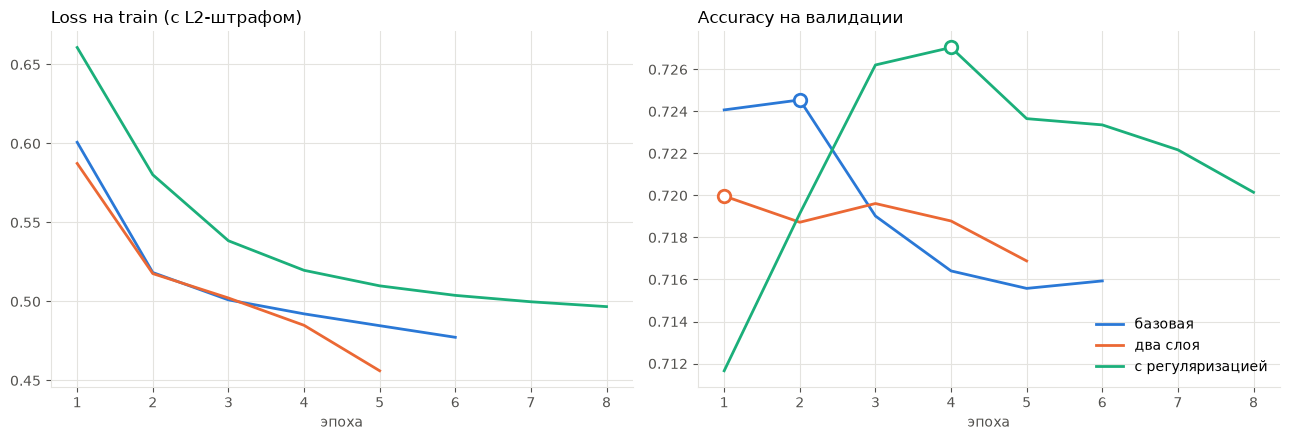

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a']
INK_SECONDARY = '#52514e'
GRID_COLOR = '#e4e3df'

fig, (ax_loss, ax_val) = plt.subplots(1, 2, figsize=(13, 4.5))

for color, (name, model) in zip(SERIES_COLORS, mlp_models.items()):
    epochs = range(1, model.n_iter_ + 1)
    best_epoch = int(np.argmax(model.validation_scores_))

    ax_loss.plot(epochs, model.loss_curve_, color=color, linewidth=2, label=name)
    ax_val.plot(epochs, model.validation_scores_, color=color, linewidth=2, label=name)
    ax_val.plot(best_epoch + 1, model.validation_scores_[best_epoch], marker='o', markersize=9,
                markerfacecolor='white', markeredgecolor=color, markeredgewidth=2)

ax_loss.set_title('Loss на train (с L2-штрафом)', loc='left')
ax_val.set_title('Accuracy на валидации', loc='left')

for ax in (ax_loss, ax_val):
    ax.set_xlabel('эпоха', color=INK_SECONDARY)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color=GRID_COLOR, linewidth=0.8)
    ax.tick_params(colors=INK_SECONDARY)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID_COLOR)

ax_val.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

**Что видно на графиках — переобучение:**
- loss на train падает у всех моделей до последней эпохи: сеть всё лучше подгоняется под обучающие твиты;
- точность на валидации сначала растёт, достигает пика и начинает падать: модель запоминает конкретные примеры вместо общих закономерностей;
- **два слоя** (~2 млн весов) переобучаются быстрее всех: лучший результат уже на 1-й эпохе (0.720), а loss на train к 5-й эпохе самый низкий —
  сеть лучше всех запоминает train и хуже всех обобщает;
- **базовая** модель достигает пика на 2-й эпохе (0.7245), после чего точность падает до 0.716;
- **с регуляризацией** стартует медленнее (0.712 после 1-й эпохи), но растёт до 4-й эпохи и показывает лучший результат (0.727):
  L2-штраф и маленький шаг обучения замедляют запоминание.

Разница между конфигурациями небольшая (0.720–0.727). Потолок качества здесь задают не размер сети, а признаки
(мешок слов не видит порядок и контекст) и шумная разметка по смайликам.

### 2.7 Итоговая модель

In [22]:
best_config = mlp_results['accuracy (val)'].idxmax()
mlp = mlp_models[best_config]

print('Итоговая конфигурация:', best_config, mlp_configs[best_config])
print('Точность на валидации:', round(mlp.best_validation_score_, 4))
print('Формы матриц весов по слоям:', [w.shape for w in mlp.coefs_])

Итоговая конфигурация: с регуляризацией {'hidden_layer_sizes': (128,), 'alpha': 0.01, 'learning_rate_init': 0.0003}
Точность на валидации: 0.727
Формы матриц весов по слоям: [(15464, 128), (128, 1)]


У итоговой модели две матрицы весов:
- `mlp.coefs_[0]` размером 15 464 × 128 — связи «слово словаря → нейрон скрытого слоя»;
- `mlp.coefs_[1]` размером 128 × 1 — связи «нейрон скрытого слоя → выход».

Именно их разберём в разделе 3, чтобы понять, какие слова модель считает позитивными и негативными.
Качество на тестовой выборке и сравнение с логистической регрессией — в разделе 4.

## 3. Интерпретация модели: анализ весов

### 3.1 Веса первого слоя

Первый слой хранит матрицу `W1` размером «слова × нейроны»: строка матрицы — это 128 весов, с которыми одно слово
передаёт сигнал в каждый нейрон скрытого слоя. Второй слой `W2` (128 × 1) говорит, с каким весом каждый нейрон голосует за выход.

Посмотрим на «сырые» веса первого слоя для нескольких слов (первые 8 нейронов из 128):

In [23]:
W1, W2 = mlp.coefs_
word_index = vectorizer.vocabulary_

sample_words = [w for w in ['обожать', 'спасибо', 'хах', 'грустно', 'болеть', 'дом'] if w in word_index]
raw_weights = pd.DataFrame(
    W1[[word_index[w] for w in sample_words], :8],
    index=sample_words,
    columns=[f'нейрон {k}' for k in range(8)],
).round(3)

print('W1:', W1.shape, '| W2:', W2.shape)
print('Нейронов, голосующих за позитив (вес в W2 > 0):', int((W2 > 0).sum()), 'из', W2.shape[0])
raw_weights

W1: (15464, 128) | W2: (128, 1)
Нейронов, голосующих за позитив (вес в W2 > 0): 62 из 128


,нейрон 0,нейрон 1,нейрон 2,нейрон 3,нейрон 4,нейрон 5,нейрон 6,нейрон 7
обожать,0.099,-0.089,-0.075,0.102,0.101,0.116,-0.092,-0.054
спасибо,0.104,-0.080,-0.084,0.129,0.096,0.128,-0.072,-0.111
хах,0.165,-0.105,-0.154,0.146,0.115,0.169,-0.129,-0.113
грустно,-0.137,0.121,0.120,-0.130,-0.121,-0.137,0.105,0.111
болеть,-0.091,0.096,0.080,-0.097,-0.099,-0.106,0.095,0.098
дом,-0.003,0.030,0.036,-0.009,-0.007,0.001,0.020,0.032


В таблице видна закономерность: у `обожать`, `спасибо` и `хах` знаки весов по нейронам совпадают, у `грустно` и `болеть` —
противоположные, а у нейтрального `дом` веса близки к нулю. Похожие по тональности слова «включают» одни и те же нейроны.

Но по одной строке `W1` нельзя сказать, позитивное слово или нет: у каждого слова есть и положительные, и отрицательные веса.
Знак веса имеет смысл только вместе с тем, за что «голосует» нейрон. Положительный вес к нейрону, который тянет выход
в негатив, означает «это слово — за негатив».

Поэтому одно число на слово получаем двумя способами.

### 3.2 Способ 1: вклад слова через оба слоя

Если не учитывать ReLU и смещения, выход сети для текста $x$ равен $x \cdot W_1 \cdot W_2$.
Тогда вклад слова $j$ — это сумма «вес слова в нейрон × вес нейрона на выход» по всем 128 нейронам:

$$\text{вклад}_j = \sum_{k=1}^{128} W_1[j, k] \cdot W_2[k]$$

В коде это одно матричное умножение `W1 @ W2`. Положительный вклад тянет к позитиву, отрицательный — к негативу.
Это линейное приближение: ReLU обнуляет отрицательные сигналы нейронов, и точный вклад зависит от остальных слов твита.

In [24]:
word_scores = pd.Series((W1 @ W2).ravel(), index=feature_names, name='вклад')
word_scores.describe().round(3).to_frame()

,вклад
count,15464.000
mean,0.089
std,0.697
min,-4.645
25%,-0.329
50%,0.122
75%,0.538
max,4.964


### 3.3 Способ 2: проверка «текст из одного слова»

Точный ответ сети без приближений можно получить, если подать на вход текст из одного слова. После нормировки
TF-IDF такой вектор содержит одну единицу на месте этого слова, а все такие векторы вместе образуют единичную матрицу.
`predict_proba` вернёт вероятность позитива для каждого слова с учётом ReLU и смещений.

Если два способа согласуются, линейному приближению можно доверять.

In [25]:
from scipy import sparse

single_word_texts = sparse.identity(len(feature_names), format='csr')
single_word_proba = pd.Series(
    mlp.predict_proba(single_word_texts)[:, 1],
    index=feature_names,
    name='P(позитив) для одного слова',
)

print('Ранговая корреляция Спирмена между способами:', round(word_scores.corr(single_word_proba, method='spearman'), 3))

Ранговая корреляция Спирмена между способами: 1.0


### 3.4 Топ-20 слов для каждого класса

В таблицах — вклад слова (способ 1), вероятность позитива для текста из одного этого слова (способ 2)
и число твитов в train со словом, чтобы видеть, что в топ попали не редкие случайные слова.

In [26]:
TOP_N = 20

word_summary = pd.DataFrame({
    'вклад': word_scores.round(3),
    'P(позитив) для одного слова': single_word_proba.round(3),
    'твитов в train': (X_train > 0).sum(axis=0).A1,
})

top_positive = word_summary.nlargest(TOP_N, 'вклад')
top_negative = word_summary.nsmallest(TOP_N, 'вклад')

probe_top_positive = set(single_word_proba.nlargest(TOP_N).index)
probe_top_negative = set(single_word_proba.nsmallest(TOP_N).index)
print('Совпадение топ-20 со способом 2: позитив', len(set(top_positive.index) & probe_top_positive),
      'из 20, негатив', len(set(top_negative.index) & probe_top_negative), 'из 20')

display(top_positive.rename_axis('топ-20 позитивных'))
display(top_negative.rename_axis('топ-20 негативных'))

Совпадение топ-20 со способом 2: позитив 18 из 20, негатив 19 из 20


,вклад,P(позитив) для одного слова,твитов в train
топ-20 позитивных,,,
хах,4.964,0.971,6164
спасибо,3.683,0.951,3298
приятно,3.578,0.953,718
ура,3.320,0.949,490
обожать,3.083,0.940,489
смех,3.012,0.936,172
ржа,3.005,0.930,131
наконец,2.940,0.935,742
рада,2.937,0.933,553


,вклад,P(позитив) для одного слова,твитов в train
топ-20 негативных,,,
жаль,-4.645,0.038,1209
обидно,-4.587,0.038,641
печально,-4.490,0.039,321
грустно,-4.368,0.041,503
жалко,-4.317,0.042,750
скучать,-4.123,0.050,1478
блин,-3.998,0.052,3300
печаль,-3.906,0.048,389
сожаление,-3.891,0.054,301


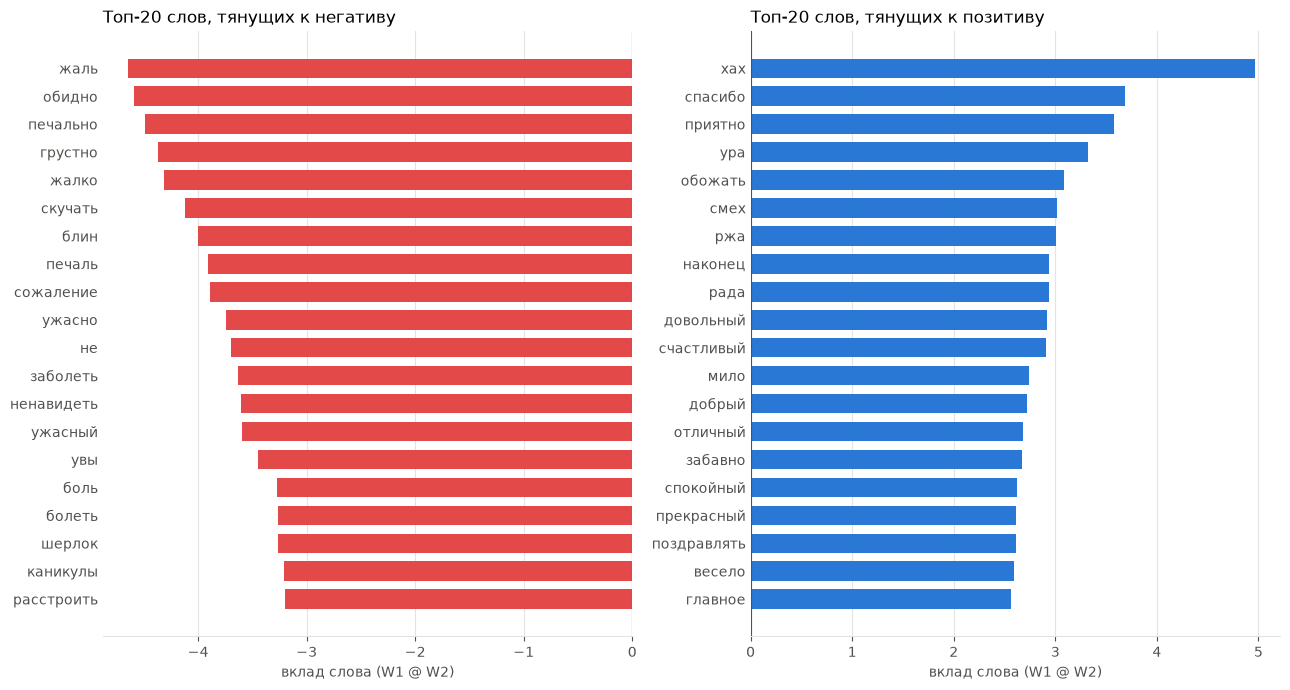

In [27]:
POSITIVE_COLOR = '#2a78d6'
NEGATIVE_COLOR = '#e34948'

fig, (ax_neg, ax_pos) = plt.subplots(1, 2, figsize=(13, 7))

for ax, top, color, title in [
    (ax_neg, top_negative, NEGATIVE_COLOR, 'Топ-20 слов, тянущих к негативу'),
    (ax_pos, top_positive, POSITIVE_COLOR, 'Топ-20 слов, тянущих к позитиву'),
]:
    ax.barh(top.index[::-1], top['вклад'][::-1], color=color, height=0.7)
    ax.set_title(title, loc='left')
    ax.set_xlabel('вклад слова (W1 @ W2)', color=INK_SECONDARY)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.8)
    ax.grid(axis='x', color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_SECONDARY)
    ax.tick_params(axis='y', length=0)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID_COLOR)

plt.tight_layout()
plt.show()

### 3.5 Насколько логично распределились слова

**Согласие способов.** Ранговая корреляция между вкладом слова и вероятностью для текста из одного слова практически равна 1,
топ-20 совпадают на 18 и 19 слов из 20. Для отдельных слов линейное приближение `W1 @ W2` надёжно.

**В целом распределение логичное:**
- позитив — радость, благодарность, смех, поздравления: `спасибо`, `ура`, `обожать`, `счастливый`, `рада`, `поздравлять`;
- негатив — грусть, сожаление, болезнь, неприязнь: `жаль`, `обидно`, `грустно`, `заболеть`, `болеть`, `ненавидеть`, `блин`;
- самое сильное позитивное слово — `хах` (смех): нормализация смеха из раздела 1.4 собрала сотни написаний в один сильный признак.

**Слова, которые сами по себе не эмоции:**
- `спокойный`, `добрый`, `главное` — части устойчивых фраз «спокойной ночи», «доброе утро», «главное, что…».
  Модель выучила формулы вежливости, которые в твитах обычно пишут со смайликом;
- `не` (49 тыс. твитов в train) — в топе негатива. Модель считает частицу негативной **сама по себе**, независимо от того,
  что она отрицает. В разделе 4 это даст ошибки на фразах вроде «неплохо» или «не грусти».

**Артефакты корпуса** (твиты собраны с 6 декабря 2013 по 20 января 2014 года):
- `шерлок` — в эти недели фанаты ждали новый сезон сериала «Шерлок» и писали «хочу быстрее новые серии((».
  Модель выучила тему момента, а не эмоцию;
- `каникулы` — зимние каникулы заканчивались: «ну почему эти каникулы так быстро прошли((». На другом периоде это слово было бы позитивным;
- `ржа` — ошибка лемматизации: сленговое «ржу» (смеюсь) pymorphy разобрал как существительное «ржа» (ржавчина).
  В позитив слово попало правильно, но под чужой леммой.

**Вывод:** веса модели отражают статистику совпадений слов со смайликами в конкретном корпусе. Там, где слово и эмоция связаны
напрямую (`грустно`, `ура`), это совпадает со смыслом. Там, где связь через контекст или тему (`не`, `шерлок`, `каникулы`),
модель выучивает корреляцию, а не значение.

## 4. Оценка качества и слабые места

### 4.1 Метрики на тестовой выборке

Тестовая выборка используется впервые. Положительный класс — **позитив** (метка 1):

- **Accuracy** — доля правильных ответов;
- **Precision** — из твитов, которые модель назвала позитивными, доля действительно позитивных;
- **Recall** — из всех позитивных твитов доля найденных моделью;
- **F1-score** — среднее гармоническое precision и recall.

Для сравнения рядом показана **логистическая регрессия** на тех же признаках — бейзлайн из одного нейрона.

In [28]:
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score


def evaluate(name, y_true, y_pred):
    return {
        'модель': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }


y_pred = mlp.predict(X_test)

baseline = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

test_results = pd.DataFrame([
    evaluate('MLP (TF-IDF, слова)', y_test, y_pred),
    evaluate('логистическая регрессия (бейзлайн)', y_test, y_pred_baseline),
]).set_index('модель').round(4)
test_results

,accuracy,precision,recall,f1
модель,,,,
"MLP (TF-IDF, слова)",0.7268,0.7248,0.7454,0.7350
логистическая регрессия (бейзлайн),0.7266,0.7221,0.7514,0.7365


In [29]:
print(classification_report(y_test, y_pred, target_names=['негатив', 'позитив'], digits=4))

              precision    recall  f1-score   support

     негатив     0.7289    0.7075    0.7180     20694
     позитив     0.7248    0.7454    0.7350     21391

    accuracy                         0.7268     42085
   macro avg     0.7269    0.7265    0.7265     42085
weighted avg     0.7268    0.7268    0.7266     42085



- MLP и логистическая регрессия дают одинаковое качество: около 72.7% правильных ответов.
  Скрытый слой со 128 нейронами не добавляет точности по сравнению с одним нейроном — потолок задают признаки и разметка;
- recall для позитива выше, чем для негатива: модель охотнее ставит «позитив».

### 4.2 Матрица ошибок

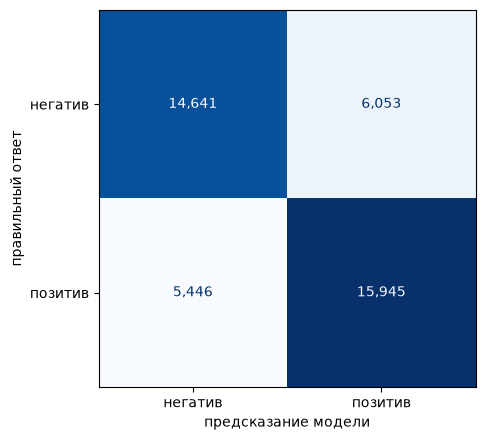

False Positive (негатив назван позитивом): 6,053
False Negative (позитив назван негативом): 5,446


In [30]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['негатив', 'позитив'], cmap='Blues', values_format=',', ax=ax, colorbar=False,
)
ax.set_xlabel('предсказание модели')
ax.set_ylabel('правильный ответ')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'False Positive (негатив назван позитивом): {fp:,}')
print(f'False Negative (позитив назван негативом): {fn:,}')

Модель чаще ошибается в сторону **позитива**: ложноположительных ошибок (FP) больше, чем ложноотрицательных (FN).
Негативный твит без явно негативных слов («опять понедельник», «завтра в школу») модель легко принимает за позитивный.

### 4.3 Ручное тестирование

Функция `predict_sentiment` прогоняет фразу через тот же пайплайн, что и обучающие данные:
очистка → лемматизация → `vectorizer.transform` → `predict_proba`. В колонке «нет в словаре» — слова, которые модель не знает
и просто игнорирует.

In [31]:
analyzer = vectorizer.build_analyzer()


def predict_sentiment(texts, model=mlp, vec=vectorizer):
    lemmas = [lemmatize(clean_text(text)) for text in texts]
    proba = model.predict_proba(vec.transform(lemmas))[:, 1]
    return pd.DataFrame({
        'фраза': texts,
        'леммы': lemmas,
        'P(негатив)': (1 - proba).round(3),
        'P(позитив)': proba.round(3),
        'итог': np.where(proba >= 0.5, 'позитив', 'негатив'),
        'нет в словаре': [', '.join(w for w in analyzer(lemma) if w not in vectorizer.vocabulary_) for lemma in lemmas],
    })


my_phrases = [
    'Обожаю этот солнечный день, всё просто супер!',
    'Спасибо большое, вы лучшие',
    'Ужасный сервис, больше никогда не приду',
    'Мне так грустно и одиноко',
    'Отлично, ещё один понедельник',
    'Спасибо, что опять опоздал на час',
    'Ну конечно, просто прекрасно - опять сломался ноутбук',
    'Еда отличная, но обслуживание ужасное',
]
predict_sentiment(my_phrases)

,фраза,леммы,P(негатив),P(позитив),итог,нет в словаре
0,"Обожаю этот солнечный день, всё просто супер!",обожать этот солнечный день все просто супер,0.054,0.946,позитив,
1,"Спасибо большое, вы лучшие",спасибо большой вы хороший,0.041,0.959,позитив,
2,"Ужасный сервис, больше никогда не приду",ужасный сервис большой никогда не прийти,0.917,0.083,негатив,
3,Мне так грустно и одиноко,я так грустно и одиноко,0.956,0.044,негатив,
4,"Отлично, ещё один понедельник",отлично еще один понедельник,0.238,0.762,позитив,
5,"Спасибо, что опять опоздал на час",спасибо что опять опоздать на час,0.645,0.355,негатив,
6,"Ну конечно, просто прекрасно - опять сломался ноутбук",ну конечно просто прекрасно опять сломаться ноутбук,0.617,0.383,негатив,
7,"Еда отличная, но обслуживание ужасное",еда отличный но обслуживание ужасный,0.652,0.348,негатив,


- явно позитивные и явно негативные фразы модель классифицирует уверенно и правильно;
- **сарказм** модель не распознаёт: «Отлично, ещё один понедельник» — позитив, потому что `отлично` — сильное позитивное слово.
  Где сарказм всё-таки угадан («опять сломался ноутбук»), это заслуга явно негативного слова `сломаться`, а не понимания иронии;
- смешанная фраза «Еда отличная, но обслуживание ужасное» получает вероятность между классами: модель просто складывает вклады слов.

### 4.4 Слабые места подхода

#### Частица «не»

In [32]:
negation_phrases = [
    'Фильм хороший', 'Фильм не хороший',
    'Фильм плохой', 'Фильм не плохой', 'Фильм неплохой',
    'Мне понравилось', 'Мне не понравилось',
    'Я болею', 'Я не болею',
    'Не грусти',
]
predict_sentiment(negation_phrases).drop(columns='нет в словаре')

,фраза,леммы,P(негатив),P(позитив),итог
0,Фильм хороший,фильм хороший,0.156,0.844,позитив
1,Фильм не хороший,фильм не хороший,0.363,0.637,позитив
2,Фильм плохой,фильм плохой,0.770,0.230,негатив
3,Фильм не плохой,фильм не плохой,0.884,0.116,негатив
4,Фильм неплохой,фильм неплохой,0.159,0.841,позитив
5,Мне понравилось,я понравиться,0.173,0.827,позитив
6,Мне не понравилось,я не понравиться,0.429,0.571,позитив
7,Я болею,я болеть,0.933,0.067,негатив
8,Я не болею,я не болеть,0.961,0.039,негатив
9,Не грусти,не грусть,0.838,0.162,негатив


In [33]:
has_ne_test = X_test_text.str.split().apply(lambda words: 'не' in words)

pd.DataFrame({
    'твитов': [has_ne_test.sum(), (~has_ne_test).sum()],
    'accuracy': [
        accuracy_score(y_test[has_ne_test], y_pred[has_ne_test]),
        accuracy_score(y_test[~has_ne_test], y_pred[~has_ne_test]),
    ],
    'доля позитива: предсказано': [y_pred[has_ne_test].mean(), y_pred[~has_ne_test].mean()],
    'доля позитива: на самом деле': [y_test[has_ne_test].mean(), y_test[~has_ne_test].mean()],
}, index=['твиты с «не»', 'твиты без «не»']).round(3)

,твитов,accuracy,доля позитива: предсказано,доля позитива: на самом деле
твиты с «не»,12336,0.689,0.339,0.407
твиты без «не»,29749,0.742,0.599,0.550


TF-IDF — «мешок слов»: он видит `не` и `плохой` по отдельности и не знает, что `не` относится к `плохой`.
В разделе 3 частица `не` оказалась в топ-20 негативных слов, поэтому:

- «Фильм не плохой» модель считает **негативным**, причём увереннее, чем «Фильм плохой»: два «негативных» слова вместо одного.
  «Фильм неплохой» — позитив: `неплохой` — отдельное слово со своим весом;
- «Я не болею» получается негативнее, чем «Я болею»;
- на тестовых твитах с «не» точность заметно ниже, а доля позитива в предсказаниях занижена:
  модель систематически тянет такие твиты в негатив.

#### Порядок слов

Для мешка слов фразы с одинаковым набором слов неразличимы, даже если смысл противоположный:

In [34]:
word_order_phrases = [
    'Я рад, что ты не болеешь',
    'Я не рад, что ты болеешь',
    'Еда отличная, но обслуживание ужасное',
    'Обслуживание ужасное, но еда отличная',
]
result = predict_sentiment(word_order_phrases).drop(columns='нет в словаре')
result['мешок слов'] = result['леммы'].str.split().apply(lambda words: ' '.join(sorted(words)))
result

,фраза,леммы,P(негатив),P(позитив),итог,мешок слов
0,"Я рад, что ты не болеешь",я рад что ты не болеть,0.594,0.406,негатив,болеть не рад ты что я
1,"Я не рад, что ты болеешь",я не рад что ты болеть,0.594,0.406,негатив,болеть не рад ты что я
2,"Еда отличная, но обслуживание ужасное",еда отличный но обслуживание ужасный,0.652,0.348,негатив,еда но обслуживание отличный ужасный
3,"Обслуживание ужасное, но еда отличная",обслуживание ужасный но еда отличный,0.652,0.348,негатив,еда но обслуживание отличный ужасный


После сортировки слов пары совпадают полностью, поэтому и вероятности одинаковые до последнего знака.

#### Незнакомые слова и нейтральные фразы

In [35]:
predict_sentiment(['Полный кринж, вайб не тот', 'Сегодня вторник'])

,фраза,леммы,P(негатив),P(позитив),итог,нет в словаре
0,"Полный кринж, вайб не тот",полный кринж вайба не тот,0.787,0.213,негатив,"кринж, вайба"
1,Сегодня вторник,сегодня вторник,0.588,0.412,негатив,


- сленга 2020-х (`кринж`, `вайб`) нет в корпусе 2013 года: модель его игнорирует, и решение определяет одна частица `не`;
- у модели нет нейтрального класса: «Сегодня вторник» обязана отнести к позитиву или негативу. Вероятность около 0.4 —
  это не «нейтрально», а слабый сдвиг от смещения модели и слова `сегодня`.

#### Самые уверенные ошибки на тестовой выборке

Твиты, где модель ошиблась с вероятностью выше 0.95. Твиты с нецензурной лексикой (их среди таких ошибок много) не выводятся.

In [36]:
OBSCENE_RE = re.compile(r'бля|пизд|ху[йяеию]|еба|ебу|сук[аи]')

test_proba = mlp.predict_proba(X_test)[:, 1]
errors = pd.DataFrame({'леммы': X_test_text.values, 'метка': y_test.values, 'P(позитив)': test_proba.round(3)})
errors['уверенность в ошибке'] = np.where(errors['метка'] == 1, 1 - errors['P(позитив)'], errors['P(позитив)'])
errors['метка'] = errors['метка'].map(LABEL_NAMES)

confident_errors = errors[~errors['леммы'].str.contains(OBSCENE_RE)].nlargest(8, 'уверенность в ошибке')
confident_errors.drop(columns='уверенность в ошибке')

,леммы,метка,P(позитив)
16930,с день рождение чувак весь сам упороть и добрый ты,негатив,0.967
6112,весь нравиться как я болеть у я нихер не болеть но я не ходить в шк тупо ничего не делать но я болеть,позитив,0.035
29882,поход не додружить как я всегда говорить жалко очень жалко,позитив,0.035
40211,пожалуйста как ты я ужасно скучать так так,позитив,0.035
1766,крид тогда хороший быть хах,негатив,0.964
25019,хах хах хах ах пойти повешаться,негатив,0.963
29959,почему я хотеться плакать,позитив,0.037
14604,кажеццо я заболеть но уже казаться выздороветь заболеть потому что весь день быть аццк плохо и все что я сделать это по,позитив,0.038


Многие «ошибки» на самом деле ошибки разметки: поздравление с днём рождения размечено как негатив,
а «почему я хотеться плакать» и «жалко очень жалко» — как позитив, потому что в исходном твите стоял смайлик «не того» знака.
Модель здесь права, а метка — нет. Отдельный случай — чёрный юмор («хах хах… пойти повешаться»): модель видит смех и ставит позитив. Это ещё одна причина,
по которой точность упирается в ~73%: часть тестовых ответов сама по себе неверна.

### 4.5 Биграммы: частичное лечение отрицаний

Если добавить в словарь пары соседних слов (`ngram_range=(1, 2)`), появятся признаки `не плохой`, `не понравиться`, `не болеть`
со своими весами. Обучим ту же архитектуру MLP на словах + биграммах и сравним.

In [37]:
%%time
bigram_vectorizer = TfidfVectorizer(min_df=5, max_df=0.5, ngram_range=(1, 2))
X_train_bigram = bigram_vectorizer.fit_transform(X_train_text)
X_test_bigram = bigram_vectorizer.transform(X_test_text)

mlp_bigram = MLPClassifier(**MLP_BASE_PARAMS, **mlp_configs[best_config]).fit(X_train_bigram, y_train)
y_pred_bigram = mlp_bigram.predict(X_test_bigram)

print('Размер словаря с биграммами:', len(bigram_vectorizer.vocabulary_))

Размер словаря с биграммами: 48593
CPU times: user 16min 32s, sys: 49 s, total: 17min 21s
Wall time: 2min 54s


In [38]:
comparison = pd.DataFrame([
    evaluate('MLP (слова)', y_test, y_pred),
    evaluate('MLP (слова + биграммы)', y_test, y_pred_bigram),
]).set_index('модель')
comparison['accuracy на твитах с «не»'] = [
    accuracy_score(y_test[has_ne_test], y_pred[has_ne_test]),
    accuracy_score(y_test[has_ne_test], y_pred_bigram[has_ne_test]),
]
comparison['accuracy на твитах без «не»'] = [
    accuracy_score(y_test[~has_ne_test], y_pred[~has_ne_test]),
    accuracy_score(y_test[~has_ne_test], y_pred_bigram[~has_ne_test]),
]
comparison.round(4)

,accuracy,precision,recall,f1,accuracy на твитах с «не»,accuracy на твитах без «не»
модель,,,,,,
MLP (слова),0.7268,0.7248,0.7454,0.7350,0.6894,0.7422
MLP (слова + биграммы),0.7406,0.7344,0.7671,0.7504,0.7218,0.7484


In [39]:
bigram_check = negation_phrases + word_order_phrases[:2]
pd.DataFrame({
    'фраза': bigram_check,
    'P(позитив): слова': predict_sentiment(bigram_check)['P(позитив)'].values,
    'P(позитив): слова + биграммы': predict_sentiment(bigram_check, mlp_bigram, bigram_vectorizer)['P(позитив)'].values,
})

,фраза,P(позитив): слова,P(позитив): слова + биграммы
0,Фильм хороший,0.844,0.820
1,Фильм не хороший,0.637,0.436
2,Фильм плохой,0.230,0.259
3,Фильм не плохой,0.116,0.341
4,Фильм неплохой,0.841,0.813
5,Мне понравилось,0.827,0.835
6,Мне не понравилось,0.571,0.253
7,Я болею,0.067,0.061
8,Я не болею,0.039,0.182
9,Не грусти,0.162,0.310


- биграммы повышают точность в основном на твитах с «не»: пары вроде `не понравиться` получают собственный вес;
- «Мне не понравилось» и «Фильм не хороший» становятся негативными, «Я рад, что ты не болеешь» и «Я не рад, что ты болеешь»
  начинают различаться;
- но это лишь частичное лечение: «Фильм не плохой» всё ещё ближе к негативу. Биграммы видят только соседние слова,
  а отрицание, сарказм и смысл фразы целиком остаются за пределами модели.

Основной моделью для отчёта остаётся MLP на словах: топ-20 в разделе 3 построен по словам, как требует задание.

### 4.6 Итоги раздела

| Слабое место | Что видно | Почему |
|---|---|---|
| частица «не» | «Фильм не плохой» — негатив; на твитах с «не» точность ниже | `не` — отдельное «негативное» слово, связи с соседним словом нет |
| порядок слов | «рад, что не болеешь» = «не рад, что болеешь» | мешок слов не хранит порядок |
| сарказм | «Отлично, ещё один понедельник» — позитив | модель видит слово `отлично`, а не иронию |
| незнакомые слова | `кринж`, `вайб` игнорируются | слов нет в словаре корпуса 2013 года |
| нет нейтрального класса | «Сегодня вторник» — уверенность около 0.4 | бинарная задача |
| шумная разметка | уверенные «ошибки» на поздравлениях | метки ставились по смайликам |

## 5. Тот же MLP на PyTorch

`MLPClassifier` прячет цикл обучения внутри `.fit()`. Здесь та же архитектура собрана вручную на PyTorch,
по структуре практики с первого занятия: класс модели, бейзлайн необученной сети, цикл обучения `forward → loss → backward → step`,
графики loss.

Отличия от практики с занятия, которые нужны для текстовой задачи:

| На занятии (Forest Covertype) | Здесь | Почему |
|---|---|---|
| 54 признака, плотная матрица | 15 464 признака, разреженная матрица | train в плотном виде занял бы ~10 ГБ даже в `float32` |
| вся выборка в сеть за один шаг | мини-батчи по 512 твитов; батч превращается в плотный тензор перед подачей в сеть | иначе не хватит памяти |
| валидация по тестовой выборке | отдельная валидационная часть train (10%) | тест используется один раз, в конце |
| 7 классов, `CrossEntropyLoss` | 1 выход, `BCEWithLogitsLoss` | для двух классов достаточно одного логита — «логита позитива» |
| GELU | ReLU + Dropout | как в sklearn-версии; Dropout — регуляризация, которой нет в `MLPClassifier` |

В Colab раздел работает быстрее на GPU, но выполняется и на CPU.
На GPU вычисления идут в другом порядке, поэтому цифры могут незначительно отличаться от запуска на CPU.

### 5.1 Устройство

In [40]:
import copy

import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device, f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')

Устройство: cpu 


### 5.2 Данные: мини-батчи из разреженной матрицы

От обучающей выборки отрезается 10% под валидацию. Функция `iterate_batches` — **генератор**: она не создаёт все батчи сразу,
а отдаёт их по одному (`yield`). В память попадает только текущий батч: 512 × 15 464 чисел ≈ 32 МБ.

In [41]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train.to_numpy(), test_size=0.1, stratify=y_train, random_state=RANDOM_STATE,
)
y_test_np = y_test.to_numpy()

BATCH_SIZE = 512
EVAL_BATCH_SIZE = 4096


def iterate_batches(X, y, batch_size, rng=None):
    indices = np.arange(X.shape[0])
    if rng is not None:
        rng.shuffle(indices)
    for start in range(0, len(indices), batch_size):
        batch = indices[start:start + batch_size]
        X_batch = torch.from_numpy(X[batch].toarray().astype(np.float32)).to(device)
        y_batch = torch.from_numpy(y[batch].astype(np.float32)).to(device)
        yield X_batch, y_batch


print('train:', X_tr.shape, '| validation:', X_val.shape, '| test:', X_test.shape)

train: (151502, 15464) | validation: (16834, 15464) | test: (42085, 15464)


### 5.3 Архитектура

Та же схема, что у sklearn-версии: 15 464 → 128 (ReLU) → 1. Между слоями добавлен `Dropout(0.5)`: при обучении
на каждом шаге случайная половина нейронов скрытого слоя «выключается», и сеть не может полагаться на отдельные нейроны.
При оценке (`model.eval()`) Dropout отключается.

Сеть возвращает **логит** — число от −∞ до +∞. Вероятность позитива получается сигмоидой: `torch.sigmoid(logit)`.

In [42]:
class SentimentMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.act = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.dropout(x)
        logits = self.fc2(x)
        return logits.squeeze(-1)


torch.manual_seed(RANDOM_STATE)
torch_model = SentimentMLP(input_dim=X_train.shape[1]).to(device)

print(torch_model)
print('Обучаемых параметров:', sum(p.numel() for p in torch_model.parameters()))

SentimentMLP(
  (fc1): Linear(in_features=15464, out_features=128, bias=True)
  (act): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=1, bias=True)
)
Обучаемых параметров: 1979649


### 5.4 Бейзлайн: необученная модель

Как на занятии: сначала смотрим, что выдаёт сеть со случайными весами. Для двух сбалансированных классов
ожидаем около 50% — угадывание монеткой. Loss при ответе «50 на 50» равен $\ln 2 \approx 0.693$.

In [43]:
criterion = nn.BCEWithLogitsLoss()


def predict_proba_torch(model, X, y):
    model.eval()
    total_loss = 0.0
    probas = []
    with torch.no_grad():
        for X_batch, y_batch in iterate_batches(X, y, EVAL_BATCH_SIZE):
            logits = model(X_batch)
            total_loss += criterion(logits, y_batch).item() * len(y_batch)
            probas.append(torch.sigmoid(logits).cpu().numpy())
    return total_loss / len(y), np.concatenate(probas)


baseline_loss, baseline_proba = predict_proba_torch(torch_model, X_val, y_val)
print(f'Необученная модель на валидации: loss {baseline_loss:.4f}, accuracy {accuracy_score(y_val, baseline_proba >= 0.5):.4f}')

Необученная модель на валидации: loss 0.6931, accuracy 0.5083


### 5.5 Цикл обучения

Каждая эпоха — проход по всем батчам train: прямой проход → loss → обнуление старых градиентов → backprop → шаг оптимизатора.
После эпохи считаются loss и accuracy на валидации. Лучшие веса сохраняются (`copy.deepcopy(state_dict())`),
обучение останавливается, если точность на валидации 3 эпохи подряд не растёт — так же, как early stopping в sklearn.

Оптимизатор `AdamW` (как на занятии), шаг обучения `3e-4`, `weight_decay=1e-2` — регуляризация весов, аналог `alpha` в sklearn.

In [44]:
%%time
optimizer = torch.optim.AdamW(torch_model.parameters(), lr=3e-4, weight_decay=1e-2)
rng = np.random.default_rng(RANDOM_STATE)

MAX_EPOCHS = 20
PATIENCE = 3

history = []
best_val_accuracy, best_state, epochs_without_improvement = 0.0, None, 0
torch_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()
    torch_model.train()
    train_loss_sum = 0.0

    for X_batch, y_batch in iterate_batches(X_tr, y_tr, BATCH_SIZE, rng):
        logits = torch_model(X_batch)
        loss = criterion(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(y_batch)

    val_loss, val_proba = predict_proba_torch(torch_model, X_val, y_val)
    val_accuracy = accuracy_score(y_val, val_proba >= 0.5)
    history.append({'epoch': epoch, 'train_loss': train_loss_sum / len(y_tr), 'val_loss': val_loss, 'val_accuracy': val_accuracy})
    print(f'Эпоха {epoch:02d} | train loss {history[-1]["train_loss"]:.4f} | val loss {val_loss:.4f} '
          f'| val accuracy {val_accuracy:.4f} | {time.time() - epoch_start:.1f} с')

    if val_accuracy > best_val_accuracy:
        best_val_accuracy, best_state, epochs_without_improvement = val_accuracy, copy.deepcopy(torch_model.state_dict()), 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f'Ранняя остановка: {PATIENCE} эпохи без улучшения')
            break

torch_train_time = time.time() - torch_start
torch_model.load_state_dict(best_state)
history = pd.DataFrame(history).set_index('epoch')
print(f'Лучшая эпоха: {history["val_accuracy"].idxmax()}, accuracy на валидации {best_val_accuracy:.4f}')

Эпоха 01 | train loss 0.6532 | val loss 0.6029 | val accuracy 0.7052 | 16.8 с


Эпоха 02 | train loss 0.5632 | val loss 0.5583 | val accuracy 0.7212 | 16.4 с


Эпоха 03 | train loss 0.5289 | val loss 0.5486 | val accuracy 0.7252 | 16.4 с


Эпоха 04 | train loss 0.5131 | val loss 0.5469 | val accuracy 0.7252 | 16.4 с


Эпоха 05 | train loss 0.5037 | val loss 0.5478 | val accuracy 0.7261 | 16.4 с


Эпоха 06 | train loss 0.4970 | val loss 0.5490 | val accuracy 0.7240 | 16.0 с


Эпоха 07 | train loss 0.4910 | val loss 0.5509 | val accuracy 0.7232 | 15.7 с


Эпоха 08 | train loss 0.4856 | val loss 0.5533 | val accuracy 0.7191 | 15.4 с
Ранняя остановка: 3 эпохи без улучшения
Лучшая эпоха: 5, accuracy на валидации 0.7261
CPU times: user 7min 34s, sys: 25.8 s, total: 8min
Wall time: 2min 11s


### 5.6 Кривые обучения

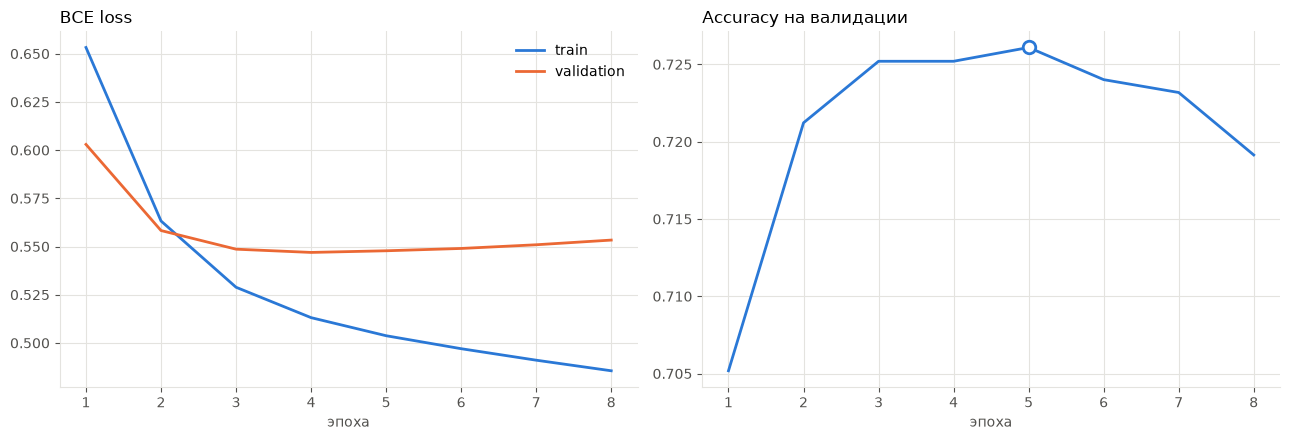

In [45]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_loss.plot(history.index, history['train_loss'], color=SERIES_COLORS[0], linewidth=2, label='train')
ax_loss.plot(history.index, history['val_loss'], color=SERIES_COLORS[1], linewidth=2, label='validation')
ax_loss.set_title('BCE loss', loc='left')
ax_loss.legend(frameon=False)

best_epoch = history['val_accuracy'].idxmax()
ax_acc.plot(history.index, history['val_accuracy'], color=SERIES_COLORS[0], linewidth=2)
ax_acc.plot(best_epoch, history.loc[best_epoch, 'val_accuracy'], marker='o', markersize=9,
            markerfacecolor='white', markeredgecolor=SERIES_COLORS[0], markeredgewidth=2)
ax_acc.set_title('Accuracy на валидации', loc='left')

for ax in (ax_loss, ax_acc):
    ax.set_xlabel('эпоха', color=INK_SECONDARY)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color=GRID_COLOR, linewidth=0.8)
    ax.tick_params(colors=INK_SECONDARY)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID_COLOR)

plt.tight_layout()
plt.show()

Картина та же, что у sklearn-версии: loss на train падает до конца, а loss на валидации после минимума начинает расти —
сеть переходит от обобщения к запоминанию. Ранняя остановка возвращает веса лучшей эпохи.

На первой эпохе train loss выше, чем на валидации. Это не ошибка: train loss усредняется по ходу эпохи, пока модель ещё учится,
и считается с включённым Dropout, а validation loss — в конце эпохи и без Dropout.

### 5.7 Качество на тестовой выборке

In [46]:
_, torch_test_proba = predict_proba_torch(torch_model, X_test, y_test_np)
y_pred_torch = (torch_test_proba >= 0.5).astype(int)

print(classification_report(y_test, y_pred_torch, target_names=['негатив', 'позитив'], digits=4))

framework_comparison = pd.DataFrame([
    evaluate('MLP sklearn', y_test, y_pred),
    evaluate(f'MLP PyTorch ({device.type})', y_test, y_pred_torch),
    evaluate('логистическая регрессия', y_test, y_pred_baseline),
]).set_index('модель').round(4)
framework_comparison['время обучения, с'] = [mlp_results.loc[best_config, 'время, с'], round(torch_train_time), '-']
framework_comparison

              precision    recall  f1-score   support

     негатив     0.7303    0.7066    0.7183     20694
     позитив     0.7248    0.7476    0.7360     21391

    accuracy                         0.7275     42085
   macro avg     0.7276    0.7271    0.7272     42085
weighted avg     0.7275    0.7275    0.7273     42085



,accuracy,precision,recall,f1,"время обучения, с"
модель,,,,,
MLP sklearn,0.7268,0.7248,0.7454,0.7350,64
MLP PyTorch (cpu),0.7275,0.7248,0.7476,0.7360,129
логистическая регрессия,0.7266,0.7221,0.7514,0.7365,-


### 5.8 Топ-слова PyTorch-модели

В PyTorch матрица весов `nn.Linear` хранится как **(выходы × входы)**, то есть транспонирована относительно `coefs_` в sklearn:
`fc1.weight` имеет форму 128 × 15 464. Поэтому вклад слова считается как `fc2.weight @ fc1.weight` → форма 1 × 15 464.

In [47]:
with torch.no_grad():
    torch_word_scores = pd.Series(
        (torch_model.fc2.weight @ torch_model.fc1.weight).cpu().numpy().ravel(),
        index=feature_names,
    )

print('fc1.weight:', tuple(torch_model.fc1.weight.shape), '| fc2.weight:', tuple(torch_model.fc2.weight.shape))
print('Совпадение топ-20 с sklearn-моделью: позитив',
      len(set(torch_word_scores.nlargest(TOP_N).index) & set(top_positive.index)), 'из 20, негатив',
      len(set(torch_word_scores.nsmallest(TOP_N).index) & set(top_negative.index)), 'из 20')

pd.DataFrame({
    'топ-10 позитивных (PyTorch)': torch_word_scores.nlargest(10).index,
    'топ-10 позитивных (sklearn)': top_positive.index[:10],
    'топ-10 негативных (PyTorch)': torch_word_scores.nsmallest(10).index,
    'топ-10 негативных (sklearn)': top_negative.index[:10],
})

fc1.weight: (128, 15464) | fc2.weight: (1, 128)
Совпадение топ-20 с sklearn-моделью: позитив 16 из 20, негатив 16 из 20


,топ-10 позитивных (PyTorch),топ-10 позитивных (sklearn),топ-10 негативных (PyTorch),топ-10 негативных (sklearn)
0,хах,хах,обидно,жаль
1,приятно,спасибо,жаль,обидно
2,спасибо,приятно,грустно,печально
3,довольный,ура,печально,грустно
4,ржа,обожать,жалко,жалко
5,ура,смех,расстроить,скучать
6,забавно,ржа,сожаление,блин
7,обожать,наконец,печаль,печаль
8,смех,рада,скучать,сожаление
9,счастливый,довольный,ужасно,ужасно


**Итоги раздела:**
- необученная сеть угадывает монеткой (accuracy ~0.51, loss ≈ ln 2 = 0.693), после 5 эпох — 0.7275 на тесте;
- PyTorch-версия даёт то же качество, что и `MLPClassifier` (0.7275 против 0.7268) и логистическая регрессия:
  способ реализации и Dropout на результат почти не влияют, потолок задают признаки TF-IDF и разметка;
- на CPU PyTorch-версия учится медленнее sklearn: каждый батч превращается из разреженной матрицы в плотную,
  и сеть умножает в основном нули. Выигрыш даёт GPU, который параллельно считает такие плотные умножения;
- топ-слова двух независимо обученных моделей совпадают на 16 из 20 для каждого класса: `хах`, `спасибо`, `приятно`
  против `обидно`, `жаль`, `грустно`. Модели с разной инициализацией и разным алгоритмом обучения выучили одну и ту же статистику слов.